## Author: Gabriel Vance
## Class: DSC630 - Predictive Analytics
## Professor: Professor Andrew Hua
## Date: October 27, 2025

# Purpose: This notebook performs the tasks outlined in 8.2 Assignment: Time Series Modeling. The tasks include plotting the data, splitting it into training and test sets, building a predictive model, making predictions, and calculating the RMSE of the model predictions on the test set.

In [7]:
# Standard library
import warnings

# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Time series modeling
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Evaluation metrics
from sklearn.metrics import mean_squared_error


# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# Ensure that all code cells are fully visible without scrolling
from IPython.core.display import display, HTML

display(HTML('''
<style>
div.CodeMirror pre {
    white-space: pre !important;
}
</style>
'''))

In [8]:
# read the CSV
df = pd.read_csv("us_retail_sales.csv")
# display the first few rows of the dataframe
df.head()

,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC
0,1992,146925,147223,146805,148032,149010,149800,150761.0,151067.0,152588.0,153521.0,153583.0,155614.0
1,1993,157555,156266,154752,158979,160605,160127,162816.0,162506.0,163258.0,164685.0,166594.0,168161.0
2,1994,167518,169649,172766,173106,172329,174241,174781.0,177295.0,178787.0,180561.0,180703.0,181524.0
3,1995,182413,179488,181013,181686,183536,186081,185431.0,186806.0,187366.0,186565.0,189055.0,190774.0
4,1996,189135,192266,194029,194744,196205,196136,196187.0,196218.0,198859.0,200509.0,200174.0,201284.0


# Plot the data with proper labeling and make some observations on the graph.


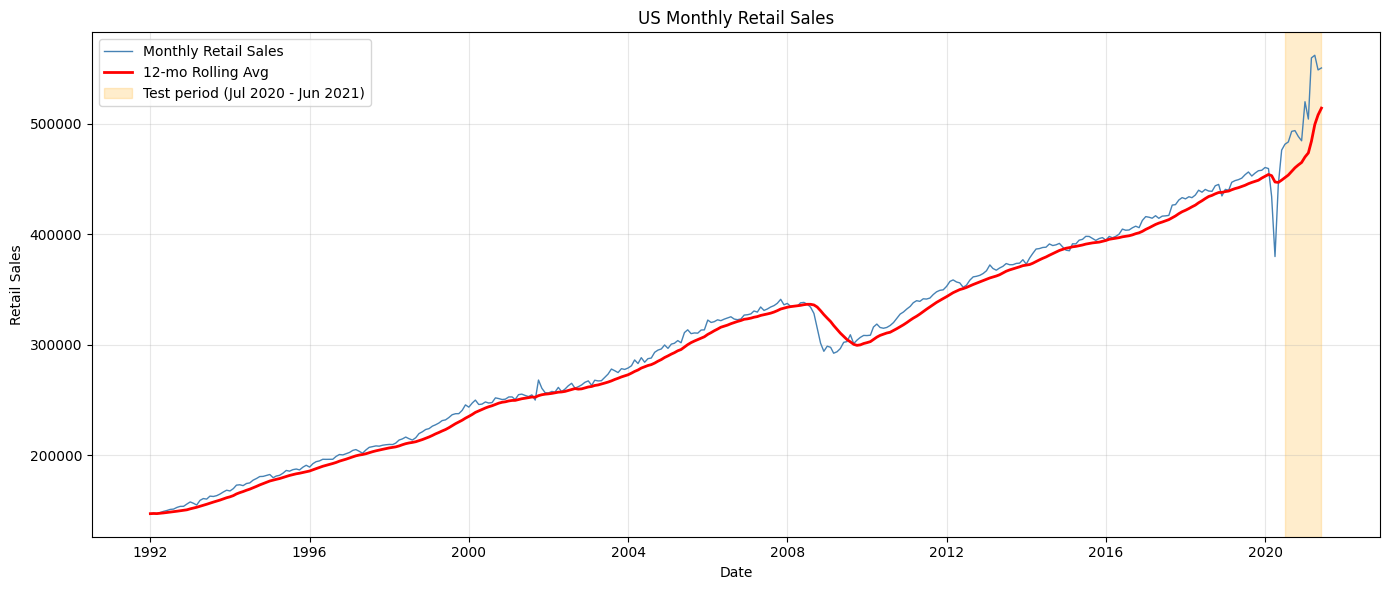

In [9]:
# reshape the wide-year/month table into a monthly time series
months = ['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC']
df_long = df.melt(id_vars='YEAR', value_vars=months, var_name='Month', value_name='Sales').dropna(subset=['Sales'])
# map month names to numbers
month_map = {m: i+1 for i, m in enumerate(months)}
df_long['MonthNum'] = df_long['Month'].map(month_map)

# create a datetime index and sort
df_long['Date'] = pd.to_datetime(dict(year=df_long['YEAR'], month=df_long['MonthNum'], day=1))
df_long = df_long.sort_values('Date').set_index('Date')

# extract the time series
ts = df_long['Sales']

# plot monthly series and 12-month rolling average
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(ts.index, ts.values, label='Monthly Retail Sales', color='steelblue', linewidth=1)
ax.plot(ts.index, ts.rolling(12, min_periods=1).mean(), label='12-mo Rolling Avg', color='red', linewidth=2)
# highlight test period Jul 2020 - Jun 2021
ax.axvspan(pd.Timestamp('2020-07-01'), pd.Timestamp('2021-06-01'), color='orange', alpha=0.2, label='Test period (Jul 2020 - Jun 2021)')

ax.set_title('US Monthly Retail Sales')
ax.set_xlabel('Date')
ax.set_ylabel('Retail Sales')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

General Observations:
1. The 12 month rolling average mostly stays below the retail sales, indicating growth. 
2. There are 2 dips. First in 2008 during the financial crisis and again, much steeper, in 2020 during the Covid-19 pandemic.
3. All in all, the uptrend is generally positive, but the last 10% have been volatile due to the pandemic. The prediction model might struggle with accuracy due to this volatility.

# Split this data into a training and test set. Use the last year of data (July 2020 – June 2021) of data as your test set and the rest as your training set.


In [10]:
# split into training and test sets (test = Jul 2020 - Jun 2021)
test_start = pd.Timestamp('2020-07-01')
test_end = pd.Timestamp('2021-06-01')

train = ts[ts.index < test_start].copy()
test = ts[(ts.index >= test_start) & (ts.index <= test_end)].copy()

print(f"Train: {train.index.min().date()} to {train.index.max().date()}  ({len(train)} months)")
print(f"Test:  {test.index.min().date()} to {test.index.max().date()}  ({len(test)} months)")


Train: 1992-01-01 to 2020-06-01  (342 months)
Test:  2020-07-01 to 2021-06-01  (12 months)


# Use the training set to build a predictive model for the monthly retail sales.


In [ ]:
# fit a seasonal ARIMA (SARIMAX) on the training series
model = SARIMAX(train,
                order=(1, 1, 1),
                seasonal_order=(1, 1, 1, 12),
                enforce_stationarity=False,
                enforce_invertibility=False)
res = model.fit(disp=False)

# forecast the test period
n_steps = len(test)
fc = res.get_forecast(steps=n_steps)
pred = fc.predicted_mean
pred.index = test.index  # align index with test

# compute RMSE on test set
rmse = np.sqrt(mean_squared_error(test, pred))

print(f"SARIMAX fitted. Test RMSE = {rmse:.2f}")

# show a small table of actual vs predicted
results_df = pd.DataFrame({"Actual": test, "Predicted": pred})
print(results_df)


SARIMAX fitted. Test RMSE = 59819.07
              Actual      Predicted
Date                               
2020-07-01  481627.0  472662.232108
2020-08-01  483716.0  469915.761881
2020-09-01  493327.0  467295.167315
2020-10-01  493991.0  469497.544046
2020-11-01  488652.0  470815.334281
2020-12-01  484782.0  467042.062226
2021-01-01  520162.0  470290.324578
2021-02-01  504458.0  469675.930288
2021-03-01  559871.0  460669.576194
2021-04-01  562269.0  436617.407935
2021-05-01  548987.0  467074.293269
2021-06-01  550782.0  482060.163826


<Figure size 640x480 with 0 Axes>

## Report the RMSE of the model predictions on the test set.


In [12]:
print(f"Test RMSE = {rmse:.2f}")

Test RMSE = 59819.07
